### Step 1: Load and Inspect the Dataset
We will load the actual dataset `/content/diabetes_prediction_dataset.csv`, inspect the columns, check for missing values, and handle duplicate rows.

In [ ]:
import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv('/content/diabetes_prediction_dataset.csv')

# Remove duplicate rows
print(f"Initial shape: {df.shape}")
df = df.drop_duplicates()
print(f"Shape after removing duplicates: {df.shape}")

# Inspect data info and head
print(df.info())
display(df.head())

Initial shape: (100000, 9)
Shape after removing duplicates: (96146, 9)
<class 'pandas.core.frame.DataFrame'>
Index: 96146 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   gender               96146 non-null  object 
 1   age                  96146 non-null  float64
 2   hypertension         96146 non-null  int64  
 3   heart_disease        96146 non-null  int64  
 4   smoking_history      96146 non-null  object 
 5   bmi                  96146 non-null  float64
 6   HbA1c_level          96146 non-null  float64
 7   blood_glucose_level  96146 non-null  int64  
 8   diabetes             96146 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 7.3+ MB
None


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


### Step 2: Separate Features and Labels, and Split the Dataset
We will define our inputs as `Features` and target as `Labels`, then perform an 80/20 train/test split.

In [ ]:
from sklearn.model_selection import train_test_split

# Separate inputs (Features) and target (Labels)
Features = df.drop(columns=['diabetes'])
Labels = df['diabetes']

# Split into training and test sets (80/20)
Features_train, Features_test, Labels_train, Labels_test = train_test_split(
    Features, Labels, test_size=0.2, random_state=42, stratify=Labels
)

print(f"Training features shape: {Features_train.shape}")
print(f"Testing features shape: {Features_test.shape}")

Training features shape: (76916, 8)
Testing features shape: (19230, 8)


### Step 3: Build the Preprocessing and Logistic Regression Pipeline
We will set up a ColumnTransformer to scale numerical columns and one-hot encode categorical features, followed by a Logistic Regression model inside a scikit-learn Pipeline.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

# Identify column types
categorical_cols = Features.select_dtypes(include=['object']).columns.tolist()
numerical_cols = Features.select_dtypes(exclude=['object']).columns.tolist()

# Define preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ]
)

# Build the pipeline with Logistic Regression
diabetes_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(random_state=42, max_iter=1000))
])

# Train the pipeline
diabetes_pipeline.fit(Features_train, Labels_train)
print("Pipeline training completed successfully!")

Pipeline training completed successfully!


### Step 4: Model Evaluation
Let's evaluate the pipeline using accuracy, precision, recall, F1-score, and a confusion matrix.

Accuracy Score: 0.9596

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.99      0.98     17534
           1       0.87      0.64      0.74      1696

    accuracy                           0.96     19230
   macro avg       0.92      0.81      0.86     19230
weighted avg       0.96      0.96      0.96     19230



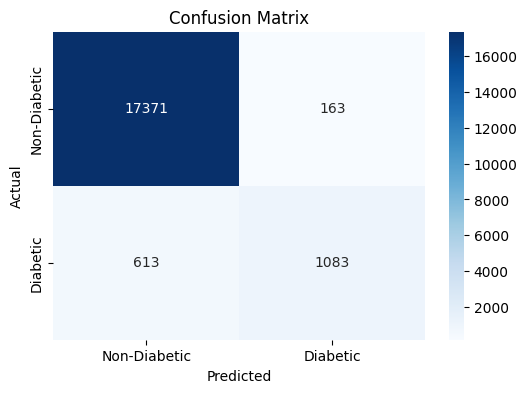

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

# Generate predictions on the test set
predictions = diabetes_pipeline.predict(Features_test)

# Calculate metrics
accuracy = accuracy_score(Labels_test, predictions)
print(f"Accuracy Score: {accuracy:.4f}\n")
print("Classification Report:")
print(classification_report(Labels_test, predictions))

# Compute and plot confusion matrix
cm = confusion_matrix(Labels_test, predictions)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Non-Diabetic', 'Diabetic'], yticklabels=['Non-Diabetic', 'Diabetic'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

### Step 5: Save and Download the Trained Pipeline
We save the entire pipeline to a file using Pickle and prepare it for local download.

In [ ]:
import pickle
from google.colab import files

# Save the pipeline as a pickle file
model_path = 'diabetes_model.pkl'
with open(model_path, 'wb') as file:
    pickle.dump(diabetes_pipeline, file)

print(f"Model pipeline successfully saved to {model_path}.")

# Trigger browser download
files.download(model_path)

Model pipeline successfully saved to diabetes_model.pkl.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Step 6: Load Saved Model and Build Interactive UI
We load the saved pipeline without retraining and build an interactive prediction dashboard using `ipywidgets`.

In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import pickle
import pandas as pd

# Load the saved model pipeline
with open('diabetes_model.pkl', 'rb') as file:
    loaded_pipeline = pickle.load(file)

# Define the input interactive widgets based on dataset schema
gender_w = widgets.Dropdown(options=['Female', 'Male', 'Other'], value='Female', description='Gender:')
age_w = widgets.FloatSlider(value=40.0, min=0.0, max=100.0, step=1.0, description='Age:')
hypertension_w = widgets.Dropdown(options=[('No', 0), ('Yes', 1)], value=0, description='Hypertension:')
heart_disease_w = widgets.Dropdown(options=[('No', 0), ('Yes', 1)], value=0, description='Heart Disease:')
smoking_w = widgets.Dropdown(options=['never', 'No Info', 'current', 'former', 'ever', 'not current'], value='never', description='Smoking:')
bmi_w = widgets.FloatText(value=27.3, description='BMI:')
hba1c_w = widgets.FloatText(value=5.5, description='HbA1c level:')
glucose_w = widgets.FloatText(value=100.0, description='Glucose:')

predict_btn = widgets.Button(description='Predict', button_style='primary')
output = widgets.Output()

def make_prediction(b):
    with output:
        clear_output()
        # Validate inputs
        if bmi_w.value <= 0 or hba1c_w.value <= 0 or glucose_w.value <= 0:
            print("Error: Please enter positive values for BMI, HbA1c, and Glucose.")
            return

        # Create a single-row DataFrame matching the original features schema
        input_data = pd.DataFrame([{
            'gender': gender_w.value,
            'age': age_w.value,
            'hypertension': int(hypertension_w.value),
            'heart_disease': int(heart_disease_w.value),
            'smoking_history': smoking_w.value,
            'bmi': bmi_w.value,
            'HbA1c_level': hba1c_w.value,
            'blood_glucose_level': glucose_w.value
        }])

        # Generate prediction using loaded model
        pred = loaded_pipeline.predict(input_data)[0]
        proba = loaded_pipeline.predict_proba(input_data)[0][1]

        # Display input summary and output results
        print("--- Input Summary ---")
        for col in input_data.columns:
            print(f"{col.capitalize()}: {input_data[col].values[0]}")
        print("\n--- Prediction Result ---")
        if pred == 1:
            print(f"Positive for Diabetes (Probability: {proba * 100:.2f}%)")
        else:
            print(f"Negative for Diabetes (Probability of negative: {(1 - proba) * 100:.2f}%)")
        print("\n*Note: This is an AI model projection and does not replace professional medical advice.*")

predict_btn.on_click(make_prediction)

# Arrange widgets
input_form = widgets.VBox([
    gender_w, age_w, hypertension_w, heart_disease_w, smoking_w, bmi_w, hba1c_w, glucose_w, predict_btn
])

display(input_form, output)

Output()

### Loading the Model in the Future Without Retraining

To use this trained model in any future Python script or Jupyter/Colab notebook without training it again, follow these steps:

1. Ensure the saved file `diabetes_model.pkl` is in your working directory.
2. Load the file using Python's built-in `pickle` library.
3. Pass your new inputs as a `pandas` DataFrame with matching column names directly into the loaded model.

In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import pandas as pd
import pickle

# 1. Load the pre-trained pipeline
with open('diabetes_model.pkl', 'rb') as file:
    loaded_pipeline = pickle.load(file)

# 2. Build form input widgets
gender_input = widgets.Dropdown(options=['Female', 'Male', 'Other'], value='Female', description='Gender:')
age_input = widgets.IntSlider(value=40, min=0, max=120, step=1, description='Age:')
hypertension_input = widgets.Dropdown(options=[('No', 0), ('Yes', 1)], value=0, description='Hypertension:')
heart_disease_input = widgets.Dropdown(options=[('No', 0), ('Yes', 1)], value=0, description='Heart Disease:')
smoking_input = widgets.Dropdown(options=['never', 'No Info', 'current', 'former', 'ever', 'not current'], value='never', description='Smoking:')
bmi_input = widgets.FloatText(value=25.0, description='BMI:')
hba1c_input = widgets.FloatText(value=5.5, description='HbA1c level:')
glucose_input = widgets.FloatText(value=100.0, description='Glucose:')

predict_button = widgets.Button(description='Predict Now', button_style='success')
output_display = widgets.Output()

# 3. Predict action callback with simple validation
def on_predict_clicked(b):
    with output_display:
        clear_output()

        # Validation check
        if bmi_input.value <= 0 or hba1c_input.value <= 0 or glucose_input.value <= 0:
            print("Validation Error: BMI, HbA1c, and Glucose must be positive numbers.")
            return

        # Organize input data into original DataFrame schema
        patient_data = pd.DataFrame([{
            'gender': gender_input.value,
            'age': float(age_input.value),
            'hypertension': int(hypertension_input.value),
            'heart_disease': int(heart_disease_input.value),
            'smoking_history': smoking_input.value,
            'bmi': bmi_input.value,
            'HbA1c_level': hba1c_input.value,
            'blood_glucose_level': glucose_input.value
        }])

        # Run prediction
        prediction = loaded_pipeline.predict(patient_data)[0]
        probability = loaded_pipeline.predict_proba(patient_data)[0][1]

        print("=== Predicted Output ===")
        if prediction == 1:
            print(f"Result: Diabetes Predicted (Probability: {probability * 100:.2f}%)")
        else:
            print(f"Result: Non-Diabetic (Probability: {(1 - probability) * 100:.2f}%)")
        print("\n*Note: This is an AI prediction model output, not a diagnostic medical report.*")

predict_button.on_click(on_predict_clicked)

# 4. Display the dashboard UI
dashboard_layout = widgets.VBox([
    widgets.HTML("<h4>Enter Patient Health Indicators:</h4>"),
    gender_input,
    age_input,
    hypertension_input,
    heart_disease_input,
    smoking_input,
    bmi_input,
    hba1c_input,
    glucose_input,
    predict_button
])

display(dashboard_layout, output_display)

Output()